# P6 – Operasi Morfologi dan Komponen Terhubung (Praktikum Computer Vision P5-P6, SIMUTEH)
**Nama:** Ramadi Hayqal Dwinugraha · **NIM:** 2230511115 · **Kelas:** 7A · **SEED:** 1115

Mengerjakan Bagian 3 (operasi morfologi), Bagian 4 (komponen terhubung dan pengukuran), dan Bagian 5 (modul `src/bercak.py`).
Jalankan dari atas ke bawah. Praproses yang dipakai milik sendiri (`src/praproses.py`).

In [1]:
from pathlib import Path
import sys, os, re, json

# 1) Pasang Google Drive (khusus Google Colab)
try:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except ImportError:
    pass

# 2) Cari folder repository simuteh-2230511115 (harus berisi src/ dan data/)
NIM = "2230511115"
DRIVE_NB = Path("/content/drive/MyDrive/Colab Notebooks")
_kand = [DRIVE_NB / f"simuteh-{NIM}", DRIVE_NB / f"simuteh-{NIM}" / f"simuteh-{NIM}",
         Path.cwd(), *Path.cwd().parents, Path(f"/content/simuteh-{NIM}")]
if DRIVE_NB.exists():
    _kand += sorted(DRIVE_NB.glob(f"*/simuteh-{NIM}"))
ROOT = next((p.resolve() for p in _kand
             if (p / "src" / "utils_cv.py").is_file() and (p / "data" / "sintetis" / "label.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Folder simuteh-2230511115 (berisi src/, data/, hasil/) belum ditemukan di "
                            "Drive Saya/Colab Notebooks. Unggah folder utuh, bukan hanya file .ipynb.")
os.chdir(ROOT / "notebook")              # semua jalur relatif pada petunjuk ("../src", "../hasil") berlaku
sys.path.insert(0, str(ROOT / "src"))

# 3) Periksa SEED = 4 digit terakhir NIM
SEED = int(re.search(r"^SEED\s*=\s*(\d+)", (ROOT / "src" / "buat_dataset_sintetis.py").read_text(), re.M).group(1))
assert str(SEED) == NIM[-4:], f"SEED {SEED} tidak sama dengan 4 digit terakhir NIM {NIM[-4:]}"
print("Repository:", ROOT, "| SEED =", SEED)

Mounted at /content/drive
Repository: /content/drive/MyDrive/Colab Notebooks/simuteh-2230511115 | SEED = 1115


In [2]:
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 20)
PARAM = json.load(open("../hasil/param_praproses.json"))
label = pd.read_csv("../data/sintetis/label.csv")
def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)
    return cv2.Canny(g, lo, hi)
print("Siap.")

Siap.


## Bagian 3. Operasi morfologi pada citra biner
### Langkah 3.1 Lembar hitung manual (diverifikasi dengan kode; piksel di luar citra = 0)

In [3]:
B = np.array([[0,0,0,0,0,0,0,0,0],
              [0,1,1,1,0,0,0,0,0],
              [0,1,0,1,0,0,0,1,0],
              [0,1,1,1,0,0,0,0,0],
              [0,0,0,0,1,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,0,0,0,0,0,0,0,0],
              [0,1,1,1,1,1,1,0,0],
              [0,0,0,0,0,0,0,0,0]], np.uint8)
S3 = np.ones((3, 3), np.uint8)
ero = lambda b: cv2.erode(b, S3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
dil = lambda b: cv2.dilate(b, S3, borderType=cv2.BORDER_CONSTANT, borderValue=0)
erosi, opening = ero(B), dil(ero(B))
closing = ero(dil(B)); closing_opening = dil(ero(closing))
print("a) komponen konektivitas 4:", cv2.connectedComponents(B, connectivity=4)[0] - 1,
      "| konektivitas 8:", cv2.connectedComponents(B, connectivity=8)[0] - 1)
for nm, m in [("b) erosi", erosi), ("b) opening", opening), ("c) closing", closing), ("d) closing lalu opening", closing_opening)]:
    print(nm); print(m)

a) komponen konektivitas 4: 4 | konektivitas 8: 3
b) erosi
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
b) opening
[[0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]
c) closing
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 1 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 0 0 0 1 0 0 0 0]
 [0 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 0 0 0 0]]
d) closing lalu opening
[[0 0 0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 1 1 1 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0 0 0]]


### Langkah 3.2 Citra biner awal (Kode 3.1)

         citra  IoU daun awal  komponen bercak awal  komponen acuan IoU bercak awal
0  teh_041.png          0.985                   165               5           0.508
1  teh_021.png          0.990                   170               3           0.174
2  teh_011.png          0.987                    92               0               -


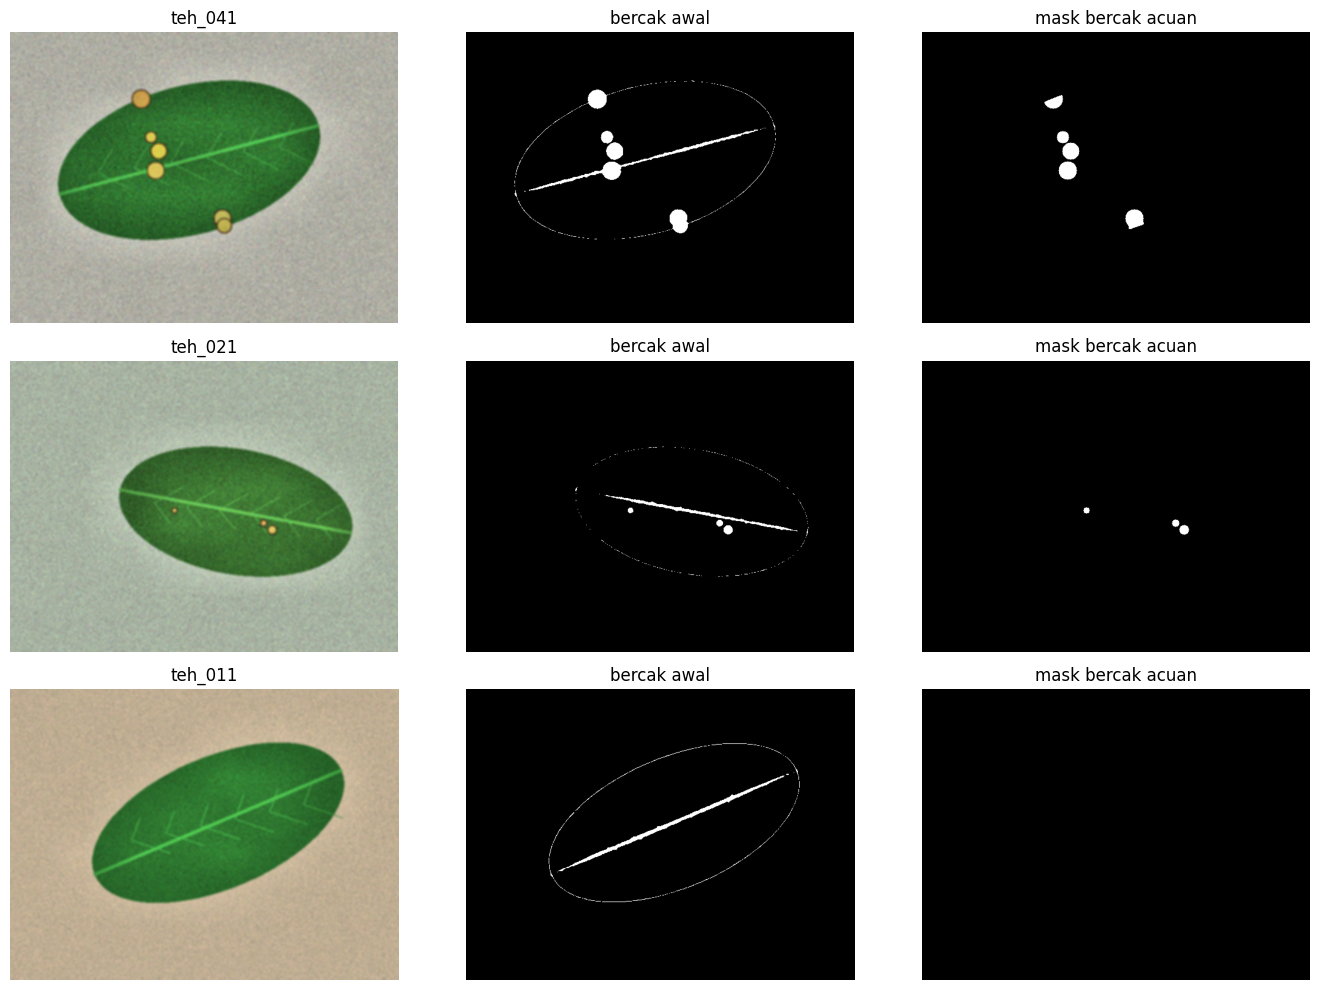

In [4]:
def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

baris, panel, judul = [], [], []
for nama in ["teh_041.png", "teh_021.png", "teh_011.png"]:       # berat, ringan, sehat
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=2, k=4.0)
    baris.append([nama, round(iou(m_daun, md), 3), jumlah_komponen(b0), jumlah_komponen(mb),
                  round(iou(b0, mb), 3) if mb.any() else "-"])
    panel += [pra_, b0, mb]; judul += [nama[:7], "bercak awal", "mask bercak acuan"]
print(pd.DataFrame(baris, columns=["citra", "IoU daun awal", "komponen bercak awal", "komponen acuan", "IoU bercak awal"]))
tampil(panel, judul, baris=3, ukuran=(14, 10))
plt.savefig("../hasil/p6_bercak_awal.png", dpi=110, bbox_inches="tight")

### Langkah 3.3 Enam operasi (Kode 3.2)

          citra     operasi  komponen  piksel    IoU
0   teh_021.png        awal       170    1940  0.174
1   teh_021.png       erosi        28     317  0.276
2   teh_021.png      dilasi        43    6021  0.065
3   teh_021.png     opening        10    1264  0.256
4   teh_021.png     closing       168    1961  0.172
5   teh_021.png  open+close         9    1269  0.255
6   teh_011.png        awal        92    3031      -
7   teh_011.png       erosi        12     656      -
8   teh_011.png      dilasi         2    8869      -
9   teh_011.png     opening         2    1934      -
10  teh_011.png     closing        90    3060      -
11  teh_011.png  open+close         1    1949      -


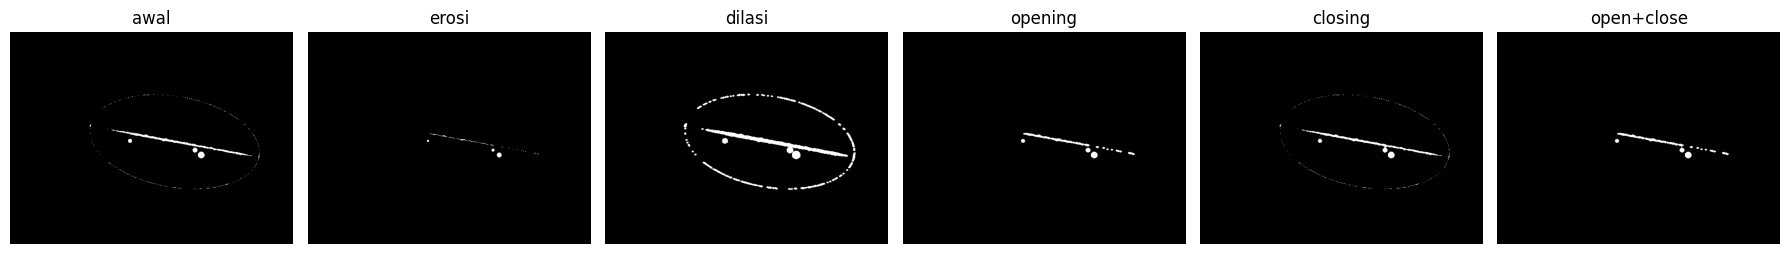

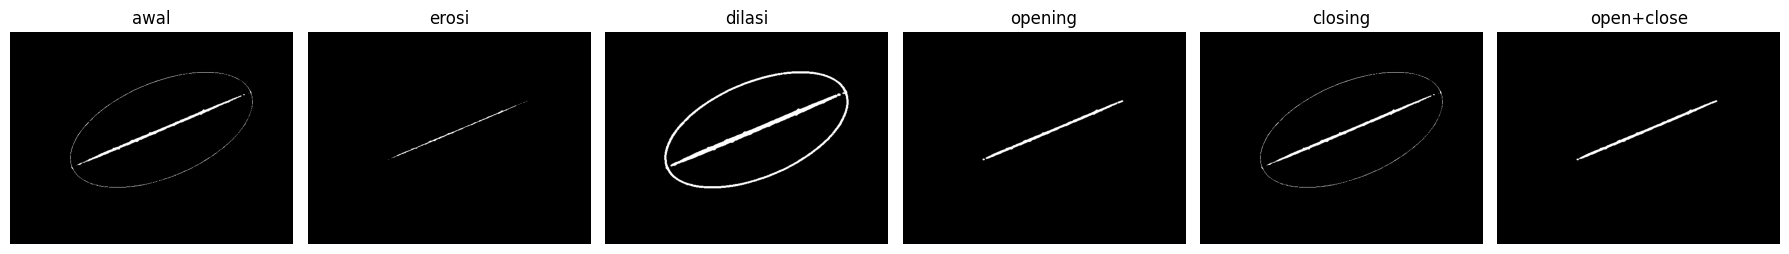

In [5]:
SE = lambda k, bentuk=cv2.MORPH_ELLIPSE: cv2.getStructuringElement(bentuk, (k, k))

def operasi(b, se):
    return {"awal": b,
            "erosi": cv2.erode(b, se),
            "dilasi": cv2.dilate(b, se),
            "opening": cv2.morphologyEx(b, cv2.MORPH_OPEN, se),
            "closing": cv2.morphologyEx(b, cv2.MORPH_CLOSE, se),
            "open+close": cv2.morphologyEx(cv2.morphologyEx(b, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)}

baris = []
for nama in ["teh_021.png", "teh_011.png"]:
    img, md, mb = muat(nama)
    pra_ = praproses(img, PARAM)
    b0 = bercak_awal(pra_, mask_daun_awal(pra_))
    hasil = operasi(b0, SE(5))
    for nm, m in hasil.items():
        baris.append([nama, nm, jumlah_komponen(m), int((m > 0).sum()), round(iou(m, mb), 3) if mb.any() else "-"])
    tampil(list(hasil.values()), list(hasil.keys()), ukuran=(18, 3))
    plt.savefig(f"../hasil/p6_operasi_{nama[:7]}.png", dpi=110, bbox_inches="tight")
print(pd.DataFrame(baris, columns=["citra", "operasi", "komponen", "piksel", "IoU"]))

### Langkah 3.4 Eksperimen k, bentuk, dan ukuran SE (Kode 3.3) → Tabel 9

In [6]:
bentuk = {"persegi": cv2.MORPH_RECT, "elips": cv2.MORPH_ELLIPSE, "silang": cv2.MORPH_CROSS}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    n_acuan = jumlah_komponen(mb)
    for k in [3, 4, 6]:
        b0 = bercak_awal(pra_, m_daun, k=k)
        for nb, kb in bentuk.items():
            for uk in [3, 5, 7]:
                se = SE(uk, kb)
                m = cv2.morphologyEx(cv2.morphologyEx(b0, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)
                baris.append([d.kelas, k, nb, uk, abs(jumlah_komponen(m) - n_acuan), iou(m, mb) if mb.any() else np.nan])
eks = pd.DataFrame(baris, columns=["kelas", "k", "bentuk", "ukuran", "galat_jumlah", "IoU"])
print(eks.pivot_table(index=["k", "bentuk", "ukuran"], columns="kelas", values=["galat_jumlah", "IoU"]).round(2))
eks.to_csv("../hasil/p6_eksperimen_se.csv", index=False)
t9 = eks[eks.k == 4].pivot_table(index=["bentuk", "ukuran"], columns="kelas", values=["IoU", "galat_jumlah"]).round(2)
t9 = t9.reindex([(b, u) for b in ["persegi", "elips", "silang"] for u in [3, 5, 7]])
print("\nTabel 9 (k = 4):"); print(t9)
t9.to_csv("../hasil/p6_tabel9.csv")

                   IoU        galat_jumlah              
kelas            berat ringan        berat ringan  sehat
k bentuk  ukuran                                        
3 elips   3       0.60   0.18         6.00   9.40  13.15
          5       0.65   0.23         3.90   3.25   4.50
          7       0.73   0.41         2.05   1.95   2.70
  persegi 3       0.60   0.19         4.20   4.80   6.60
          5       0.68   0.30         2.15   2.45   2.95
          7       0.78   0.63         0.90   1.00   1.65
  silang  3       0.60   0.18         6.00   9.40  13.15
          5       0.65   0.23         5.55   5.10   7.05
          7       0.73   0.39         4.10   4.20   4.05
4 elips   3       0.68   0.28         5.50   8.50  10.50
          5       0.73   0.42         3.25   2.95   2.50
          7       0.78   0.63         1.20   1.20   1.60
  persegi 3       0.69   0.30         4.35   4.30   5.10
          5       0.76   0.53         1.55   2.60   2.20
          7       0.79   0.70  

### Langkah 3.5 Gradien morfologi vs Canny untuk tepi daun (Kode 3.4)

In [7]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    grad = cv2.morphologyEx(m_daun, cv2.MORPH_GRADIENT, SE(3))      # dilasi - erosi
    canny = tepi_canny(cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY))
    ad = tepi_acuan(md)
    baris.append([d.kondisi_cahaya, skor_tepi(grad, ad)[2], skor_tepi(canny, ad)[2]])
gm = pd.DataFrame(baris, columns=["kondisi", "F1 gradien morfologi", "F1 Canny"]).groupby("kondisi").mean().round(3)
print(gm); print("rerata:", gm.mean().round(3).to_dict())

                F1 gradien morfologi  F1 Canny
kondisi                                       
bayangan                       0.993     0.869
gelap                          0.993     0.756
kontras_rendah                 0.940     0.913
normal                         0.991     0.728
terang                         0.978     0.874
rerata: {'F1 gradien morfologi': 0.979, 'F1 Canny': 0.828}


### Langkah 3.6 Panel elemen penstruktur (Kerjakan sendiri)

SE elips 3x3 == SE silang 3x3 ? True


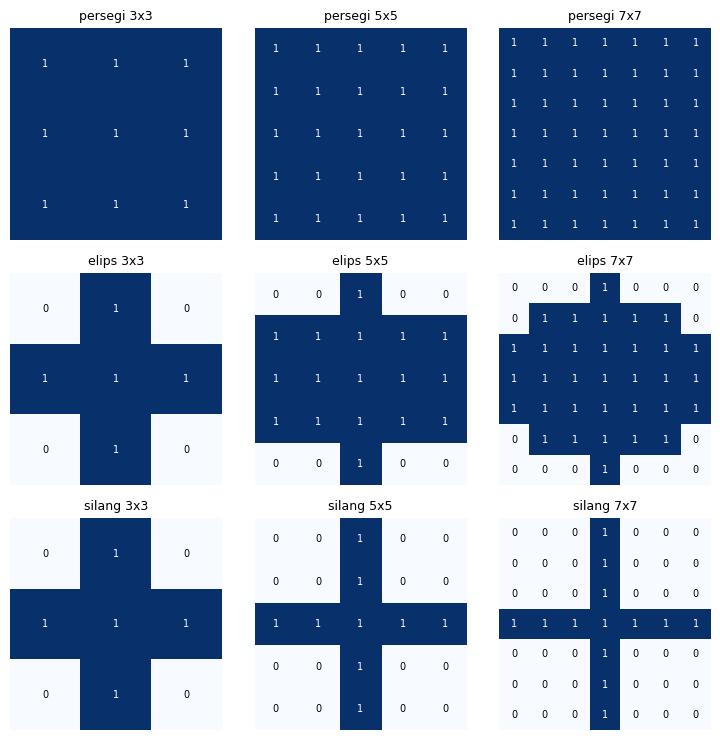

In [8]:
fig, ax = plt.subplots(3, 3, figsize=(7.5, 7.5))
for i, (nb, kb) in enumerate(bentuk.items()):
    for j, uk in enumerate([3, 5, 7]):
        se = cv2.getStructuringElement(kb, (uk, uk))
        ax[i, j].imshow(se, cmap="Blues", vmin=0, vmax=1)
        for (yy, xx), v in np.ndenumerate(se):
            ax[i, j].text(xx, yy, int(v), ha="center", va="center", fontsize=7, color="k" if v == 0 else "w")
        ax[i, j].set_title(f"{nb} {uk}x{uk}", fontsize=9); ax[i, j].axis("off")
plt.tight_layout(); plt.savefig("../hasil/p6_panel_se.png", dpi=130, bbox_inches="tight")
print("SE elips 3x3 == SE silang 3x3 ?", np.array_equal(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)),
                                                         cv2.getStructuringElement(cv2.MORPH_CROSS, (3, 3))))

## Bagian 4. Komponen terhubung dan pengukuran bercak
### Langkah 4.1 Lembar hitung manual (diverifikasi dengan kode)

In [9]:
MM_PER_PX = 0.4375      # dari lembar hitung P2: Z = 200 mm, lebar kerja 640 px

def keliling_sisi(m):
    """Keliling = jumlah sisi piksel objek yang berbatasan dengan latar (di luar citra = latar)."""
    p = np.pad((m > 0).astype(int), 1)
    return int(sum(((p[1:-1, 1:-1] == 1) & (np.roll(p, s, axis=ax)[1:-1, 1:-1] == 0)).sum()
                   for ax in (0, 1) for s in (1, -1)))

blok = np.zeros_like(B); blok[1:4, 1:4] = 255; blok[2, 2] = 255        # bercak 3x3 (hasil 3.1 d)
garis = np.zeros_like(B); garis[7, 1:7] = 255                           # garis 1 x 6
print("hasil 3.1 d sama dengan blok 3x3:", np.array_equal((closing_opening > 0), (blok > 0)))
for nm, m in [("bercak 3x3", blok), ("garis 1x6", garis)]:
    A = int((m > 0).sum()); P = keliling_sisi(m)
    kont, _ = cv2.findContours((m > 0).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    w, h = cv2.minAreaRect(kont[0])[1]
    print(f"{nm}: luas={A} px = {A*MM_PER_PX**2:.3f} mm2 | keliling(sisi)={P} | kebulatan={4*np.pi*A/P**2:.3f} | "
          f"rasio aspek={max(w,h)/max(min(w,h),1):.1f} | arcLength OpenCV={cv2.arcLength(kont[0], True):.1f} "
          f"-> kebulatan OpenCV={4*np.pi*A/cv2.arcLength(kont[0], True)**2:.3f}")

hasil 3.1 d sama dengan blok 3x3: True
bercak 3x3: luas=9 px = 1.723 mm2 | keliling(sisi)=12 | kebulatan=0.785 | rasio aspek=1.0 | arcLength OpenCV=8.0 -> kebulatan OpenCV=1.767
garis 1x6: luas=6 px = 1.148 mm2 | keliling(sisi)=14 | kebulatan=0.385 | rasio aspek=5.0 | arcLength OpenCV=10.0 -> kebulatan OpenCV=0.754


### Langkah 4.2 Label dan ukur (Kode 4.1) → Tabel 10

konektivitas 4: 14 komponen
konektivitas 8: 14 komponen
    label  luas_px  luas_mm2  keliling_px  kebulatan  rasio_aspek   cx   cy
0       1      775    148.34        101.5       0.95         1.03  216  110
1       2     1824    349.12        287.7       0.28         1.63  239  206
2       3      152     29.09         88.1       0.25         6.52  430  174
3       4      354     67.76        158.2       0.18        11.60  374  189
4       5        1      0.19          0.0       0.00         0.00  410  180
5       6      103     19.71         58.3       0.38         4.92  324  202
6       7        1      0.19          0.0       0.00         0.00  338  199
7       8       17      3.25         13.7       1.15         1.25  262  219
8       9       72     13.78         43.8       0.47         3.46  193  237
9      10      164     31.39         82.8       0.30         6.44  164  244
10     11        1      0.19          0.0       0.00         0.00  183  240
11     12       22      4.21    

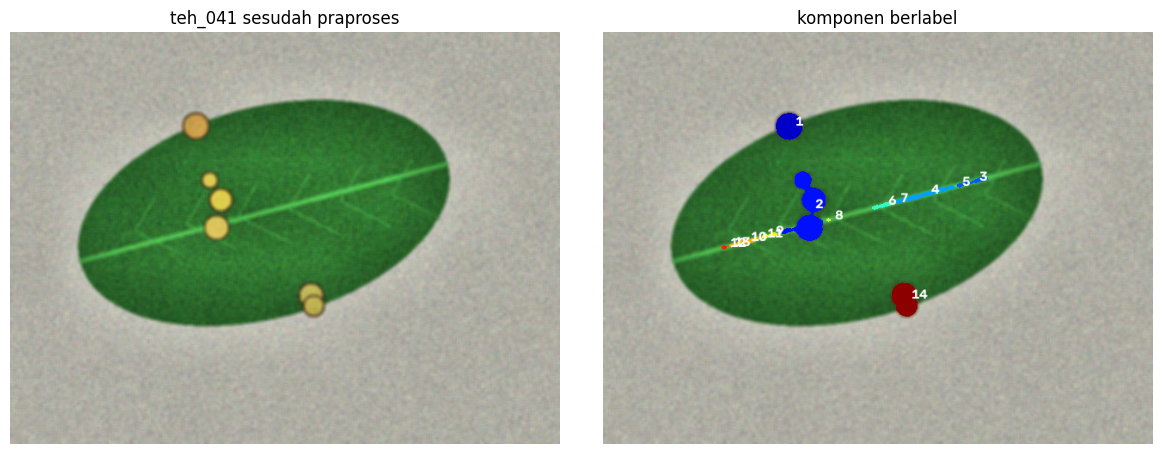

In [10]:
def ukur_komponen(m, konek=8):
    n, lbl, st, cen = cv2.connectedComponentsWithStats((m > 0).astype(np.uint8), connectivity=konek)
    baris = []
    for i in range(1, n):
        kontur, _ = cv2.findContours((lbl == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * A / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        baris.append([i, A, round(A * MM_PER_PX ** 2, 2), round(keliling, 1), round(kebulatan, 2),
                      round(rasio, 2), int(cen[i][0]), int(cen[i][1])])
    kolom = ["label", "luas_px", "luas_mm2", "keliling_px", "kebulatan", "rasio_aspek", "cx", "cy"]
    return pd.DataFrame(baris, columns=kolom), lbl

img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
for konek in [4, 8]:
    print(f"konektivitas {konek}: {jumlah_komponen(bersih, konek)} komponen")
tabel_kom, lbl = ukur_komponen(bersih)
print(tabel_kom)
tabel_kom.to_csv("../hasil/p6_tabel10_teh041.csv", index=False)
warna = cv2.applyColorMap((lbl * (255 // max(lbl.max(), 1))).astype(np.uint8), cv2.COLORMAP_JET)
warna[lbl == 0] = pra_[lbl == 0]
for _, r in tabel_kom.iterrows():
    cv2.putText(warna, str(int(r.label)), (int(r.cx) + 8, int(r.cy)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 2)
tampil([pra_, warna], ["teh_041 sesudah praproses", "komponen berlabel"], ukuran=(12, 4.5))
plt.savefig("../hasil/p6_komponen_berlabel.png", dpi=130, bbox_inches="tight")

### Langkah 4.3 Penyaringan bercak palsu (Kode 4.2) → Tabel 11

In [11]:
def saring(m, luas_min=20, bulat_min=0.5, rasio_maks=1.8):
    tabel_k, lbl = ukur_komponen(m)
    lolos = tabel_k[(tabel_k.luas_px >= luas_min) & (tabel_k.kebulatan >= bulat_min) & (tabel_k.rasio_aspek <= rasio_maks)]
    return (np.isin(lbl, lolos.label.values) * 255).astype(np.uint8), lolos

aturan = {"tanpa saring": (0, 0, 99), "luas >= 20": (20, 0, 99),
          "luas + kebulatan": (20, 0.5, 99), "luas + kebulatan + rasio": (20, 0.5, 1.8)}
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    m_daun = mask_daun_awal(pra_)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, m_daun), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    for nm, (a, b, r) in aturan.items():
        f, _ = saring(bersih, a, b, r)
        baris.append([d.kelas, nm, jumlah_komponen(f), jumlah_komponen(mb)])
uji = pd.DataFrame(baris, columns=["kelas", "aturan", "jumlah", "acuan"])
uji["galat"] = (uji.jumlah - uji.acuan).abs()
t11 = uji.pivot_table(index="aturan", columns="kelas", values="galat").round(2).reindex(list(aturan))
print(t11)
print("Daun sehat yang masih memiliki bercak palsu:")
pal = uji[uji.kelas == "sehat"].assign(palsu=lambda t: t.jumlah > 0).groupby("aturan").palsu.sum().reindex(list(aturan))
print(pal)
t11.assign(sehat_palsu=pal).to_csv("../hasil/p6_tabel11.csv")

kelas                     berat  ringan  sehat
aturan                                        
tanpa saring               3.25    2.95   2.50
luas >= 20                 2.40    2.10   1.95
luas + kebulatan           2.00    1.15   0.90
luas + kebulatan + rasio   1.35    0.50   0.25
Daun sehat yang masih memiliki bercak palsu:
aturan
tanpa saring                14
luas >= 20                  13
luas + kebulatan             8
luas + kebulatan + rasio     3
Name: palsu, dtype: int64


### Langkah 4.4 Dasar ambang penyaringan (Kerjakan sendiri): diagram sebar komponen benar vs palsu

status               benar    palsu
luas_px     count   183.00   181.00
            mean    359.41   184.60
            std     293.88   432.11
            min      33.00     1.00
            25%     162.50    17.00
            50%     291.00    36.00
            75%     474.00   103.00
            max    1929.00  2691.00
kebulatan   count   183.00   181.00
            mean      0.94     0.71
            std       0.13     0.41
            min       0.11     0.00
            25%       0.94     0.31
            50%       0.97     0.87
            75%       1.01     1.13
            max       1.11     1.15
rasio_aspek count   183.00   181.00
            mean      1.11     5.11
            std       0.32     8.82
            min       1.00     0.00
            25%       1.00     1.25
            50%       1.00     1.89
            75%       1.07     4.41
            max       4.63    45.89
status
benar    183
palsu    181
Name: count, dtype: int64
Komponen palsu:
            nama   kelas 

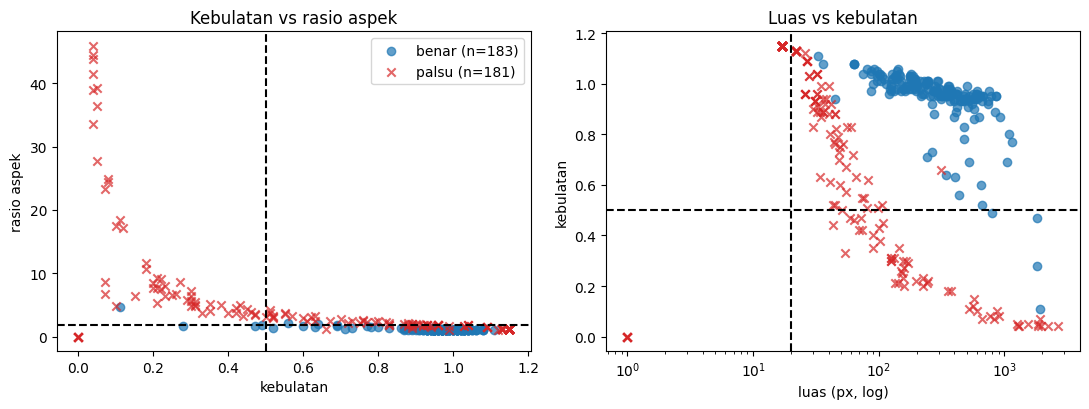

In [12]:
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    bersih = cv2.morphologyEx(cv2.morphologyEx(bercak_awal(pra_, mask_daun_awal(pra_)), cv2.MORPH_OPEN, SE(5)), cv2.MORPH_CLOSE, SE(5))
    tk, lb = ukur_komponen(bersih)
    for _, r in tk.iterrows():
        frac = float((mb[lb == r.label] > 0).mean())
        baris.append([d.nama_file, d.kelas, r.luas_px, r.kebulatan, r.rasio_aspek, "benar" if frac > 0.5 else "palsu"])
kk = pd.DataFrame(baris, columns=["nama", "kelas", "luas_px", "kebulatan", "rasio_aspek", "status"])
print(kk.groupby("status")[["luas_px", "kebulatan", "rasio_aspek"]].describe().round(2).T)
print(kk.status.value_counts())
print("Komponen palsu:"); print(kk[kk.status == "palsu"].round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for st, c, mk in [("benar", "tab:blue", "o"), ("palsu", "tab:red", "x")]:
    s = kk[kk.status == st]
    ax[0].scatter(s.kebulatan, s.rasio_aspek, c=c, marker=mk, label=f"{st} (n={len(s)})", alpha=.7)
    ax[1].scatter(s.luas_px, s.kebulatan, c=c, marker=mk, label=st, alpha=.7)
ax[0].axvline(0.5, ls="--", c="k"); ax[0].axhline(1.8, ls="--", c="k")
ax[0].set_xlabel("kebulatan"); ax[0].set_ylabel("rasio aspek"); ax[0].legend(); ax[0].set_title("Kebulatan vs rasio aspek")
ax[1].axvline(20, ls="--", c="k"); ax[1].axhline(0.5, ls="--", c="k"); ax[1].set_xscale("log")
ax[1].set_xlabel("luas (px, log)"); ax[1].set_ylabel("kebulatan"); ax[1].set_title("Luas vs kebulatan")
plt.tight_layout(); plt.savefig("../hasil/p6_sebar_komponen.png", dpi=130, bbox_inches="tight")

Bukti untuk P4.4: luas total bercak hasil dibandingkan dengan mask acuan pada teh_041.

In [13]:
img, md, mb = muat("teh_041.png")
pra_ = praproses(img, PARAM)
m_daun = mask_daun_awal(pra_)
for nm, k_open, k_close in [("tanpa morfologi", 0, 0), ("opening+closing SE 5", 5, 5)]:
    b0 = bercak_awal(pra_, m_daun)
    if k_open: b0 = cv2.morphologyEx(b0, cv2.MORPH_OPEN, SE(k_open))
    if k_close: b0 = cv2.morphologyEx(b0, cv2.MORPH_CLOSE, SE(k_close))
    f, _ = saring(b0)
    A_h, A_a = int((f > 0).sum()), int((mb > 0).sum())
    print(f"{nm}: luas hasil={A_h} px, acuan={A_a} px, selisih={100*(A_h-A_a)/A_a:+.1f}%, IoU={iou(f, mb):.3f}")
R = pra_[:, :, 2].astype(float)
cincin = (cv2.dilate(mb, SE(7)) > 0) & (cv2.erode(mb, SE(5)) == 0) & (mb == 0)
print("rerata kanal R: pusat bercak =", R[cv2.erode(mb, SE(5)) > 0].mean().round(1),
      "| cincin tepi bercak (luar mask) =", R[cincin & (m_daun > 0)].mean().round(1),
      "| daun sehat =", R[(m_daun > 0) & (cv2.dilate(mb, SE(9)) == 0)].mean().round(1))

tanpa morfologi: luas hasil=2666 px, acuan=2821 px, selisih=-5.5%, IoU=0.617
opening+closing SE 5: luas hasil=1726 px, acuan=2821 px, selisih=-38.8%, IoU=0.346
rerata kanal R: pusat bercak = 194.4 | cincin tepi bercak (luar mask) = 68.4 | daun sehat = 47.5


## Bagian 5. Integrasi: modul `src/bercak.py`
Modul sudah dilengkapi (TODO 1-7) di `src/bercak.py`. Parameter final ditentukan dari eksperimen berikut (bentuk dan ukuran SE pada pipeline lengkap, k = 4 dan 5).

In [ ]:
import importlib, bercak
importlib.reload(bercak)
baris = []
cache = {}
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file); cache[d.nama_file] = praproses(img, PARAM)
for k in [3, 4, 5]:
    for nb in ["elips", "persegi", "silang"]:
        for uk in [3, 5, 7]:
            PBx = {"k": k, "se_bentuk": nb, "se_open": uk, "se_close": uk}
            ek = []
            for _, d in label.iterrows():
                h = bercak.analisis_daun(cache[d.nama_file], PBx)
                ek.append([d.kelas, d.persen_bercak, h["persen_bercak"], h["kelas"]])
            ek = pd.DataFrame(ek, columns=["kelas", "pa", "pp", "kp"])
            ek["ka"] = ek.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
            baris.append([k, nb, uk, round((ek.pp - ek.pa).abs().mean(), 3), round(ek[["pp", "pa"]].corr().iloc[0, 1], 3),
                          round((ek.kp == ek.ka).mean(), 3), int(((ek.ka == "Sehat") & (ek.kp != "Sehat")).sum()),
                          int(((ek.ka != "Sehat") & (ek.kp == "Sehat")).sum())])
scan = pd.DataFrame(baris, columns=["k", "bentuk", "ukuran", "MAE_persen", "korelasi", "akurasi", "sehat_dinilai_bercak", "bercak_dinilai_sehat"])
print(scan.sort_values(["akurasi", "MAE_persen"], ascending=[False, True]).head(10).to_string(index=False))
scan.to_csv("../hasil/p6_scan_parameter.csv", index=False)

### Langkah 5.2 Evaluasi menyeluruh (Kode 5.2) dengan parameter final

In [ ]:
importlib.reload(bercak)
PB = {"k": 4.0, "se_bentuk": "elips", "se_open": 3, "se_close": 3, "luas_min": 20}   # parameter final
bercak.simpan_param(PB)
baris = []
for _, d in label.iterrows():
    img, md, mb = muat(d.nama_file)
    h = bercak.analisis_daun(praproses(img, PARAM), PB)
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", (ev.kelas_prediksi == ev.kelas_acuan).mean().round(3))
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print(ev.assign(benar=ev.kelas_prediksi == ev.kelas_acuan).groupby("kondisi").benar.mean().round(2))
print("Galat jumlah bercak rerata per kelas:")
print((ev.jumlah_prediksi - ev.jumlah_acuan).abs().groupby(ev.kelas).mean().round(2))
plt.figure(figsize=(5, 5))
for kl, c in [("sehat", "tab:green"), ("ringan", "tab:orange"), ("berat", "tab:red")]:
    s = ev[ev.kelas == kl]; plt.scatter(s.persen_acuan, s.persen_prediksi, c=c, label=kl)
plt.plot([0, 8], [0, 8], "k--"); plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi"); plt.legend()
plt.savefig("../hasil/p6_sebar_persen.png", dpi=130, bbox_inches="tight")
print("Bias persen (prediksi - acuan) per kelas:"); print((ev.persen_prediksi - ev.persen_acuan).groupby(ev.kelas).mean().round(3))
print("teh_041:"); print(ev[ev.nama == "teh_041.png"][["persen_acuan", "persen_prediksi", "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"]])
print(open("../hasil/param_bercak.json").read())

### Langkah 5.3 Analisis kesalahan (Kerjakan sendiri)

In [ ]:
salah = ev[ev.kelas_prediksi != ev.kelas_acuan]
panel, judul, diag = [], [], []
for _, r in salah.iterrows():
    img, md, mb = muat(r.nama)
    pra_ = praproses(img, PARAM)
    h = bercak.analisis_daun(pra_, PB)
    panel += [pra_, h["mask_bercak"], mb]
    judul += [f"{r.nama[:7]} {r.kondisi}", f"hasil: {r.kelas_prediksi}", f"acuan: {r.kelas_acuan}"]
    kk_ = bercak.bersihkan(bercak_awal(pra_, h["mask_daun"], kanal=2, k=PB["k"]), {**bercak.PARAM_BERCAK, **PB})
    diag.append([r.nama, r.kondisi, r.persen_acuan, r.persen_prediksi, r.jumlah_acuan, r.jumlah_prediksi,
                 int((mb > 0).sum()), int((h["mask_bercak"] > 0).sum()), round(iou(h["mask_bercak"], mb), 3),
                 jumlah_komponen(kk_)])
tampil(panel, judul, baris=len(salah), ukuran=(12, 3.4 * len(salah)))
plt.savefig("../hasil/p6_citra_salah.png", dpi=110, bbox_inches="tight")
print(pd.DataFrame(diag, columns=["nama", "kondisi", "persen_acuan", "persen_pred", "jml_acuan", "jml_pred",
                                  "luas_acuan_px", "luas_hasil_px", "IoU", "komponen_sebelum_saring"]).to_string(index=False))

### Pelengkap P5.2: batas kelas dari data latih saja (bukan dari seluruh label)

In [ ]:
ev["no"] = ev.nama.str.extract(r"(\d+)").astype(int)
latih, uji_ = ev[ev.no % 2 == 1], ev[ev.no % 2 == 0]
mx = lambda df, k: df[df.kelas == k].persen_prediksi
b_ringan = round((mx(latih, "sehat").max() + mx(latih, "ringan").min()) / 2, 3)
b_berat = round((mx(latih, "ringan").max() + mx(latih, "berat").min()) / 2, 3)
def kelas_dari(p, br, bb): return "Bercak Berat" if p >= bb else ("Bercak Ringan" if p >= br else "Sehat")
for nm, (br, bb) in {"batas bawaan (0,1 / 2,0)": (0.1, 2.0), "batas dari data latih": (b_ringan, b_berat)}.items():
    akur_l = (latih.persen_prediksi.apply(kelas_dari, args=(br, bb)) == latih.kelas_acuan).mean()
    akur_u = (uji_.persen_prediksi.apply(kelas_dari, args=(br, bb)) == uji_.kelas_acuan).mean()
    print(f"{nm}: batas=({br}, {bb}) akurasi latih={akur_l:.3f} akurasi uji={akur_u:.3f}")

### Langkah 5.4 dan 5.5
Tabel 13 (justifikasi parameter) ada di laporan, merujuk Tabel 9, 11, 12 dan `hasil/p6_scan_parameter.csv`.

Checkpoint (terminal repository): perbarui `README.md`, lalu
```
git add . && git commit -m "P6: morfologi, komponen terhubung, bercak.py"
git tag v0.3-morfologi && git push && git push --tags
```